# Árboles de decisión
---

## Tipos de árboles

* Árboles de decisión
    * Árboles de clasificación
    * Árboles de regresión

## Árbol de decisión (Decision Tree)

* Es el **término general** que describe la estructura del modelo. Elementos del árbol:
    * **nodos de decisión** (característica k y umbral t que permite hacer una subdivisión en datos binarios) y
    * **hojas** que representan resultados
* Se usa tanto para clasificación como para regresión

## Árbol de clasificación (Classification Tree)

* Se usa cuando la **variable objetivo es categórica** (por ejemplo, "apto/no apto", "tipo de alimento", "contaminado/no contaminado")
* **Ejemplo**: Predecir si un alimento está contaminado según sus características químicas
* Las hojas del árbol contienen **clases**

## Árbol de regresión (Regression Tree)

* Se usa cuando la **variable objetivo es continua** (por ejemplo, concentración de nitritos, temperatura, precio)
* **Ejemplo**: Predecir el nivel de nitritos en un embutido
* Las hojas del árbol contienen **valores numéricos**

## Resumen

* Elementos de Árboles de decisión:
    * **Nodos de decisión**: característica k y umbral t
    * **Hojas**

| Tipos         | Variable objetivo | Hojas             |
| --            | --                | --                |
| Clasificación | categórica        | clases            |
| Regresión     | continua          | valores numéricos |

## Idea

* La idea es encontrar fronteras de decisión
* Se van generando particiones binarias sobre la región de interés, buscando que cada nueva partición genere un subconjunto de datos lo mas homogéneo posible
* OBJETIVO: obtener subconjuntos que pertenezcan en lo posible a una sola categoría

# Árboles de clasificación
---

## Entrenamiento y visualización de un árbol de decisión

1. Se visualizan gráficos de dispersión por pares de variables (combinatoria de número de variables tomadas de a dos: C(4,2) = 4!/(2! * (4-2)!) = 6)
2. Se elije el gráfico que tiene los grupos mejor separados (en este caso: largo y ancho del pétalo por especie)
3. Se divide el gráfico por rectas verticales (largo del pétalo) u horizontales (ancho del pétalo) que mejor separe los grupos
4. Se define condición (largo del pétalo < 2.45) -> Setosa
5. Se definen umbrales

Un árbol de clasificación va a buscar **UMBRALES**
* La primera condición es la condición 0 (NODO RAIZ o PRINCIPAL)
* Todas la particiones son binarias
    * 1ra partición binaria: en este ejemplo hay hoja y NODO INTERNO o SECUNDARIO
    * 2da partición binaria: en este ejemplo hay dos hojas
* Profundidad, en este caso es 2

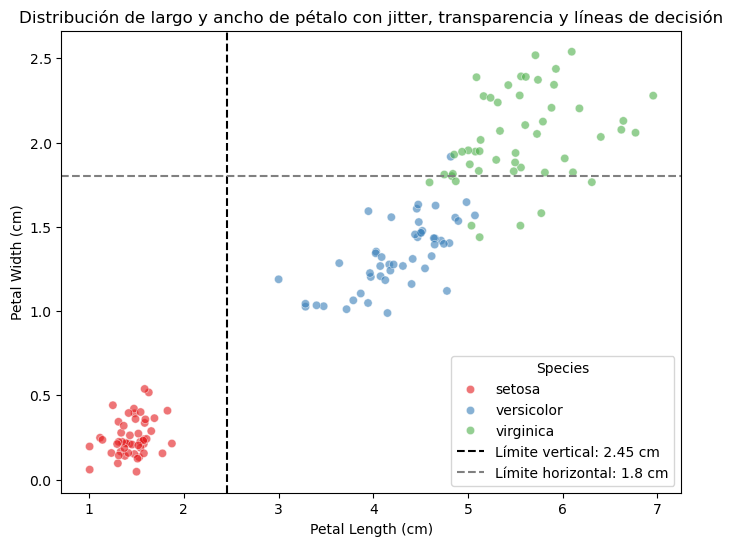

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
import seaborn as sns
import pandas as pd
import numpy as np

# Cargar el dataset Iris
iris = load_iris()

# Crear un DataFrame con las dos características y la especie
df = pd.DataFrame(iris.data[:, 2:], columns=['petal length (cm)', 'petal width (cm)'])
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

# Agregar jitter (ruido pequeño) para evitar superposición
np.random.seed(42)
df['petal length (cm)'] += np.random.normal(0, 0.05, size=len(df))
df['petal width (cm)'] += np.random.normal(0, 0.05, size=len(df))

# Graficar con seaborn usando transparencia
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='petal length (cm)', y='petal width (cm)', hue='species', palette='Set1', alpha=0.6)

# Agregar líneas de decisión
plt.axvline(x=2.45, color='black', linestyle='--', label='Límite vertical: 2.45 cm')
plt.axhline(y=1.8, color='gray', linestyle='--', label='Límite horizontal: 1.8 cm')

# Personalización del gráfico
plt.title('Distribución de largo y ancho de pétalo con jitter, transparencia y líneas de decisión')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend(title='Species')
plt.show()

Algoritmo **CART**: algoritmo de clasificación

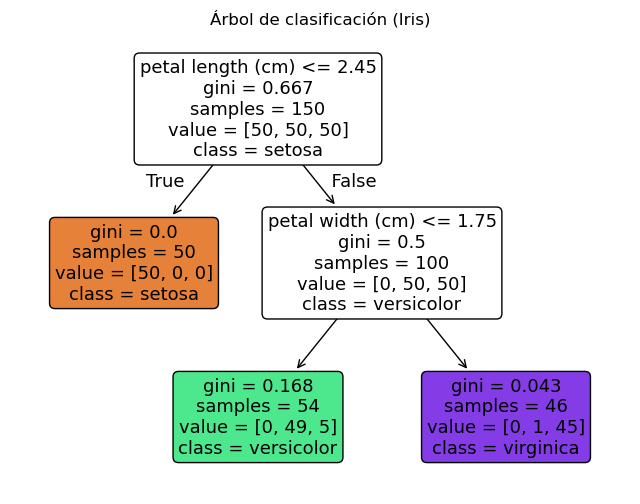

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

# Cargar el dataset Iris
iris = load_iris()

# Usar solo las dos características de pétalo
X = iris.data[:, 2:]  # petal length y petal width,toma todas las columnas desde la posición 2 en adelante (índice basado en 0).
y = iris.target

# Crear y entrenar el árbol de clasificación
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X, y)

# Visualizar el árbol
plt.figure(figsize=(8, 6))
plot_tree(tree_clf,
          feature_names=iris.feature_names[2:],  # Solo las dos variables
          class_names=iris.target_names,
          filled=True,
          rounded=True)
plt.title("Árbol de clasificación (Iris)")
plt.show()

* Nodos: 2
    * principal (raiz)
    * secundario (interno)
* Hojas: 3
* Profundidad: es la trayectoria mas larga entre la raíz y una de las hojas. Este árbol tiene 2 niveles de profundidad
* En los nodos, el class es por default y sale del primer valor (value) mayor a 0. No tiene sentido esa info
* En las hojas, el class es la clasificación

## Validación visual

* El árbol tiene errores? SI
* ¿Hay puntos que quedarían mal clasificados con esas reglas? SI (5 virginicas como versicolor y 1 versicolor como virginica)
* ¿Cómo se podría ajustar los umbrales para mejorar la separación? NO
* ¿Qúe ventajas tiene usar reglas simples basadas en variables?
* ¿Qué limitaciones ves si los datos estuvieran más mezclados?  

## Índice Gini

* Grado de impureza de un nodo $G_i$

$$G_i = 1 - \Sigma^K_{k=1} p^2_{i,k}$$

* k: número de clases, 3
* i: número de nodos, 2
* $p_{i,k}$: proporción de instancias de la clase k entre las instancias de entrenamiento en el nodo j

* **Interpretación**:
    * Si todas las observaciones pertenecen a una sola clase => $𝑝_𝑖$ = 1 => 𝐺𝑖𝑛𝑖 = 0 (**nodo puro**)
    * Si las clases están distribuidas uniformemente => el Gini es máximo (**más impuro**)
* El grado de impureza va **disminuyendo** desde la raíz hacia las hojas
* Se calcula también en los nodos porque el índice de Gini da una idea de como voy avanzando en el procesamiento y después sirve para generar una evaluación de costos que sirve para el algoritmo CART
* Es un **Modelo de caja blanca** frente a Modelo de caja negra. Se puede interpretar que está pasando con el modelo

* **Rango de valores**
    * **Mínimo = 0**. Nodo **puro**: todos los elementos pertenecen a la misma clase (Es una clasificación perfecta)
        * Nodo con 100% de una clase => $Gini = 0$ 
    * **Máximo** depende del número de clases:
        * Para 2 clases (binario): $𝐺𝑖𝑛𝑖_{max} = 0.5$ (las dos clases están en proporción 50%-50%)
        * Para k clases: $𝐺𝑖𝑛𝑖_{max} = 1 - \dfrac{1}{k}$ (todas las clases están igualmente representadas)
        * Nodo con 3 clases $Gini = 1 - (0.33^2 + 0.33^2 + 0.33^2) = 0.67$ 

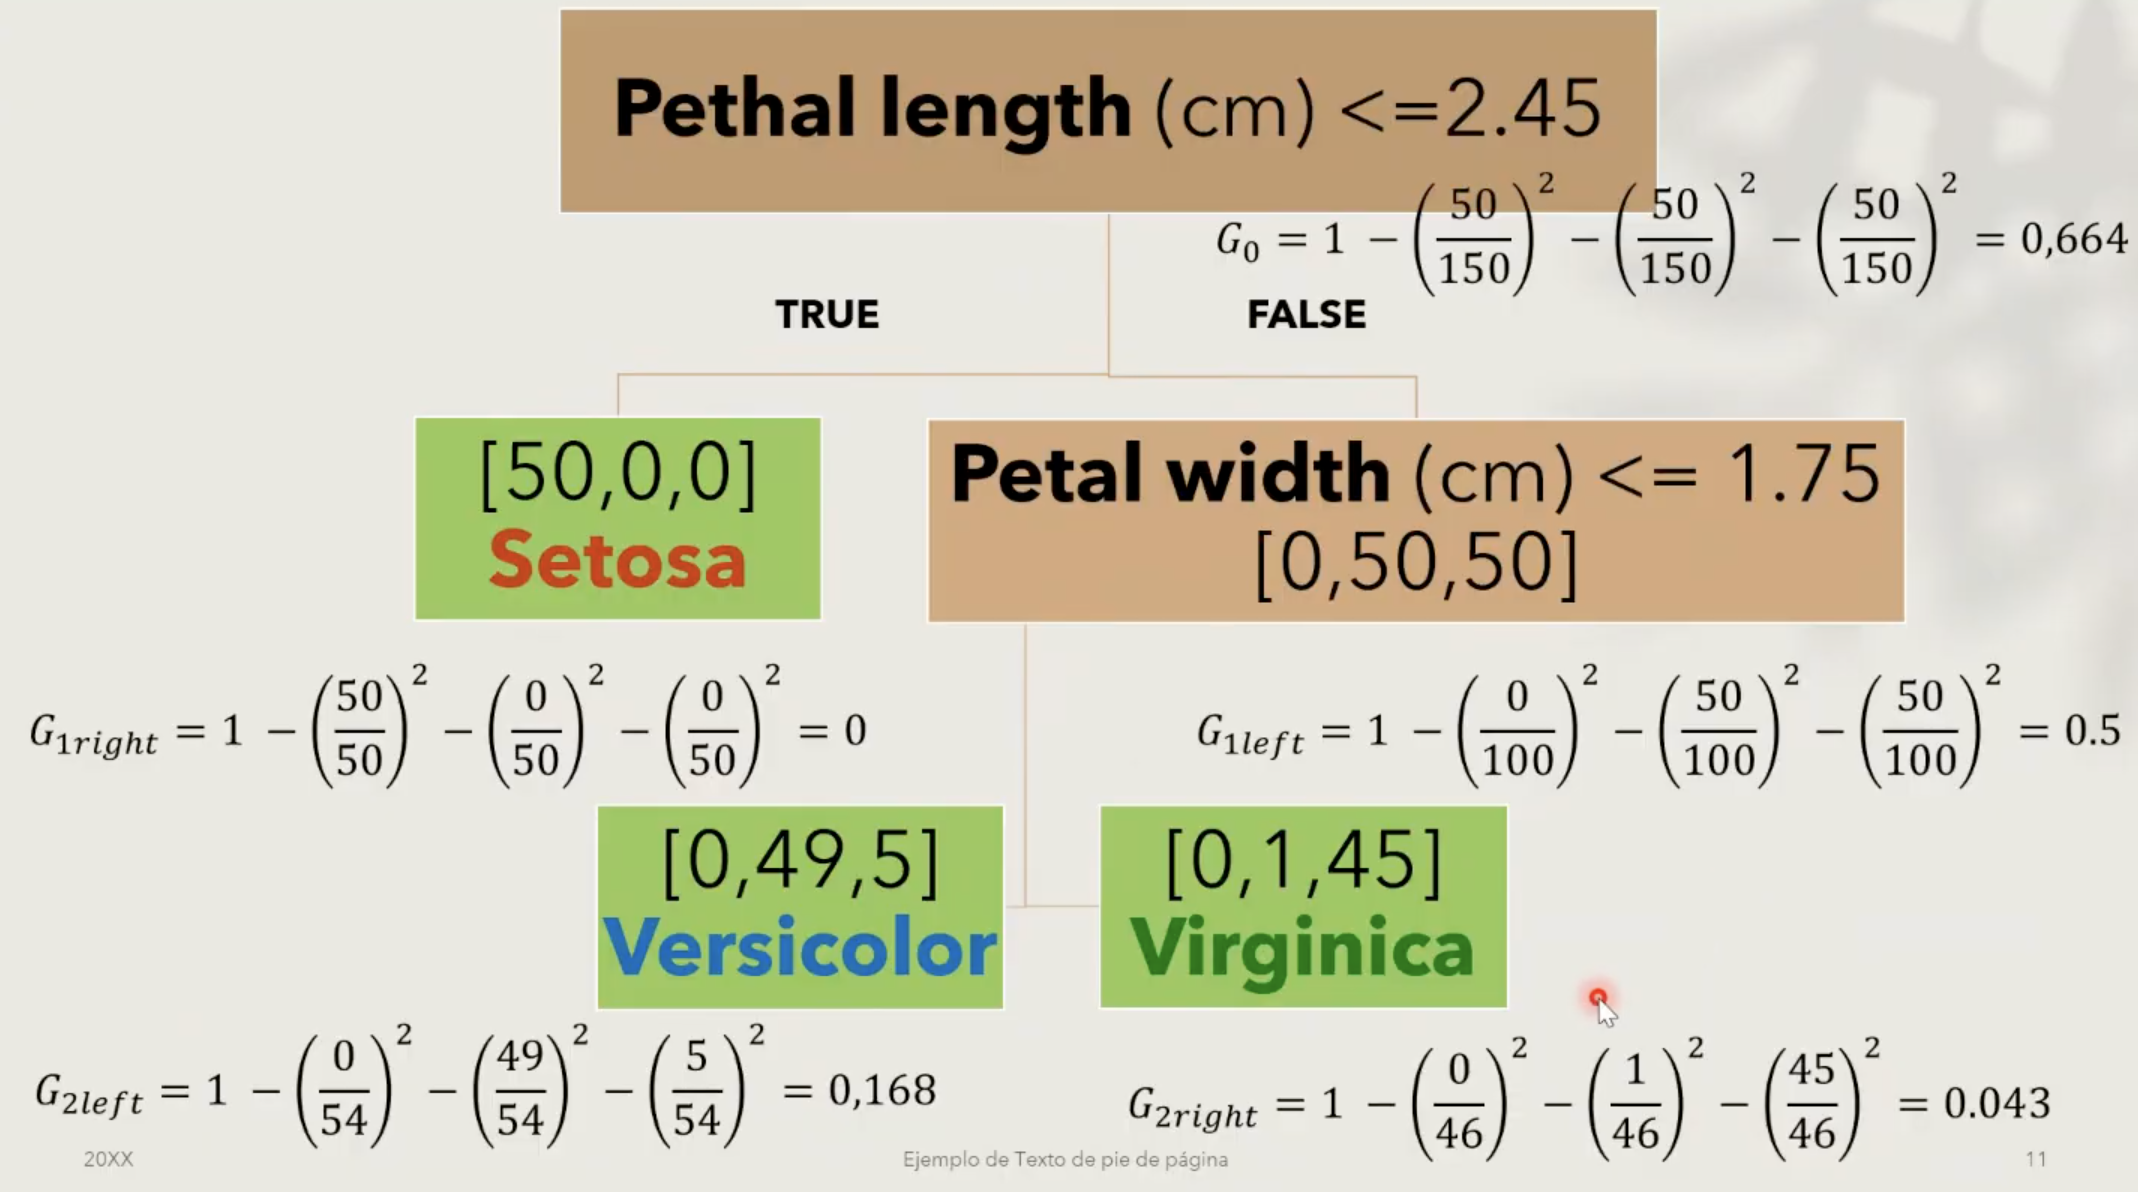

* Se observa que indice **Gini DISMINUYE a medida que aumenta la profundidad**

* **En Iris**:
    * $G_0 = 1 - (\dfrac{50}{150})^2 - (\dfrac{50}{150})^2 - (\dfrac{50}{150})^2 = 0.664$
    * $G_{1left} = 1 - (\dfrac{50}{50})^2 - (\dfrac{0}{50})^2 - (\dfrac{0}{50})^2 = 0$
    * $G_{1right}  = 1 - (\dfrac{0}{100})^2 - (\dfrac{50}{100})^2 - (\dfrac{50}{100})^2 = 0.5$
    * $G_{2left} = 1 - (\dfrac{0}{54})^2 - (\dfrac{49}{54})^2 - (\dfrac{5}{54})^2 = 0.168$
    * $G_{2right}  = 1 - (\dfrac{0}{46})^2 - (\dfrac{1}{46})^2 - (\dfrac{45}{46})^2 = 0.043$

## Información en un nodo

* **Condición de división (variable y umbral)**: Ejemplo: petal length ≤ 2.45 regla que separa los datos en ese nodo
* **Impureza (Gini o Entropía)**: Valor que indica qué tan mezcladas están las clases en el nodo. Algoritmo CART usa Gini. La idea es que las hojas sean lo mas puras posibles y que tengan la menor entropía (medida de desorden)
* **Número de muestras (samples)**: Cantidad de observaciones que llegaron a ese nodo
* **Distribución de clases (value)**. Ejemplo: [50, 0, 0] para tres clases (Setosa, Versicolor, Virginica). Muestra cuántos elementos de cada clase hay en el nodo
* **Clase predicha (class)**: La clase mayoritaria en ese nodo

## Estimación de probabilidades de clase

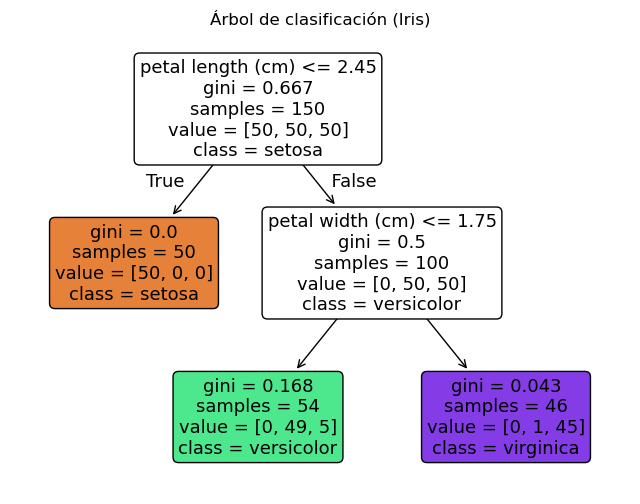

In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

# Cargar el dataset Iris
iris = load_iris()

# Usar solo las dos características de pétalo
X = iris.data[:, 2:]  # petal length y petal width,toma todas las columnas desde la posición 2 en adelante (índice basado en 0).
y = iris.target

# Crear y entrenar el árbol de clasificación
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X, y)

# Visualizar el árbol
plt.figure(figsize=(8, 6))
plot_tree(tree_clf,
          feature_names=iris.feature_names[2:],  # Solo las dos variables
          class_names=iris.target_names,
          filled=True,
          rounded=True)
plt.title("Árbol de clasificación (Iris)")
plt.show()

* Se ha encontrado una flor cuyos pétalos miden: **5 cm de largo** y **1,5 cm de ancho**
* El nodo hoja correspondiente es el nodo situado a la izquierda de la profundidad 2, por lo que el árbol de decisión debería generar las siguientes probabilidades:
    * **0%** para Iris **setosa (0/54)**,
    * **90,7%** para Iris **versicolor (49/54)** y
    * **9,3%** para Iris **virginica (5/54)**
* Y si se le pide que prediga la clase, debería generar Iris **versicolor** (clase 1) porque tiene la **mayor probabilidad**

In [4]:
# Calcula las probabilidades de que la muestra 
# [petal length = 5, petal width = 1.5] pertenezca a cada clase
tree_clf.predict_proba([[5, 1.5]])

array([[0.        , 0.90740741, 0.09259259]])

* Significa:
    * **Clase 0 (setosa)**: 0%
    * **Clase 1 (versicolor)**: 90.7%
    * **Clase 2 (virginica)**: 9.3%
* Esto se calcula según la proporción de muestras en la hoja del árbol donde cae el punto

In [5]:
# Devuelve la clase predicha para esa muestra
tree_clf.predict([[5, 1.5]]) # predice la clase 1 => versicolor, porque es la clase con mayor probabilidad

array([1])

* Significa que el modelo predice la clase **1 => versicolor**. porque es la clase con mayor probabilidad

## Algoritmo de entrenamiento CART

* El algoritmo funciona dividiendo primero el conjunto de entrenamiento en dos subconjuntos mediante una
**característica k y un umbral t** (por ejemplo: "longitud del pétalo ≤ 2,45 cm")
* ¿Cómo elige 𝒌 y 𝒕? Busca el par (𝑘, 𝑡) que produce los subconjuntos más puros (ponderados por su tamaño)
* **Minimiza** la siguiente función de costo (es una función ponderada de los dos nodos hijos por la cantidad de elementos que hay en cada uno de los nodos)

$$J(k, t_k) = \dfrac{m_{left}}{m}G_{left} + \dfrac{m_{right}}{m}G_{right}$$

* $G$: mide la impureza del subconjunto izquierdo / derecho
* $m$: número de instancias en el subconjunto izquierdo / derecho

* Es un **greedy algorithm** (algoritmo voraz)
    * Elije en cada paso la opción que parece mejor en ese momento, sin considerar el impacto futuro
    * Es decir, **toma decisiones localmente óptimas** esperando que lleven a una solución globalmente óptima

* **Características**:
    * **Simple y rápido**: porque no explora todas las posibilidades
    * **No siempre garantiza la mejor solución global**, pero funciona bien en problemas donde la elección local óptima conduce a la solución óptima global (propiedad de optimalidad)

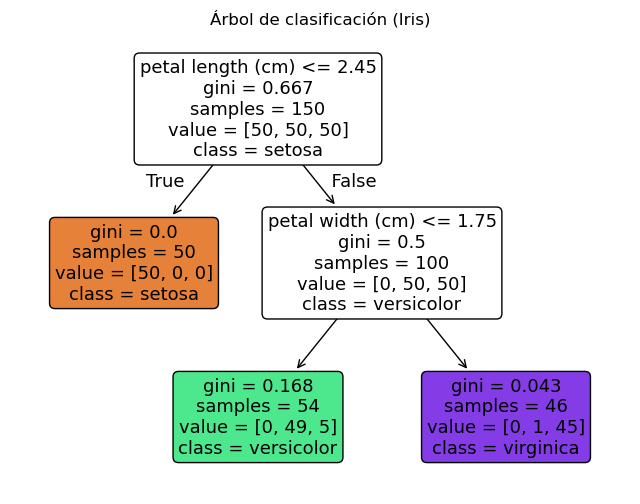

In [6]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

# Cargar el dataset Iris
iris = load_iris()

# Usar solo las dos características de pétalo
X = iris.data[:, 2:]  # petal length y petal width,toma todas las columnas desde la posición 2 en adelante (índice basado en 0).
y = iris.target

# Crear y entrenar el árbol de clasificación
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_clf.fit(X, y)

# Visualizar el árbol
plt.figure(figsize=(8, 6))
plot_tree(tree_clf,
          feature_names=iris.feature_names[2:],  # Solo las dos variables
          class_names=iris.target_names,
          filled=True,
          rounded=True)
plt.title("Árbol de clasificación (Iris)")
plt.show()

* Cálculo de la función de costo al pasar de la profundidad 0 a la 1

$$J(k=1, t_1=2.45) = \dfrac{50 + 0 + 0}{150} * 0 + \dfrac{0 + 50 + 50}{150} * 0.5 = 0.333$$

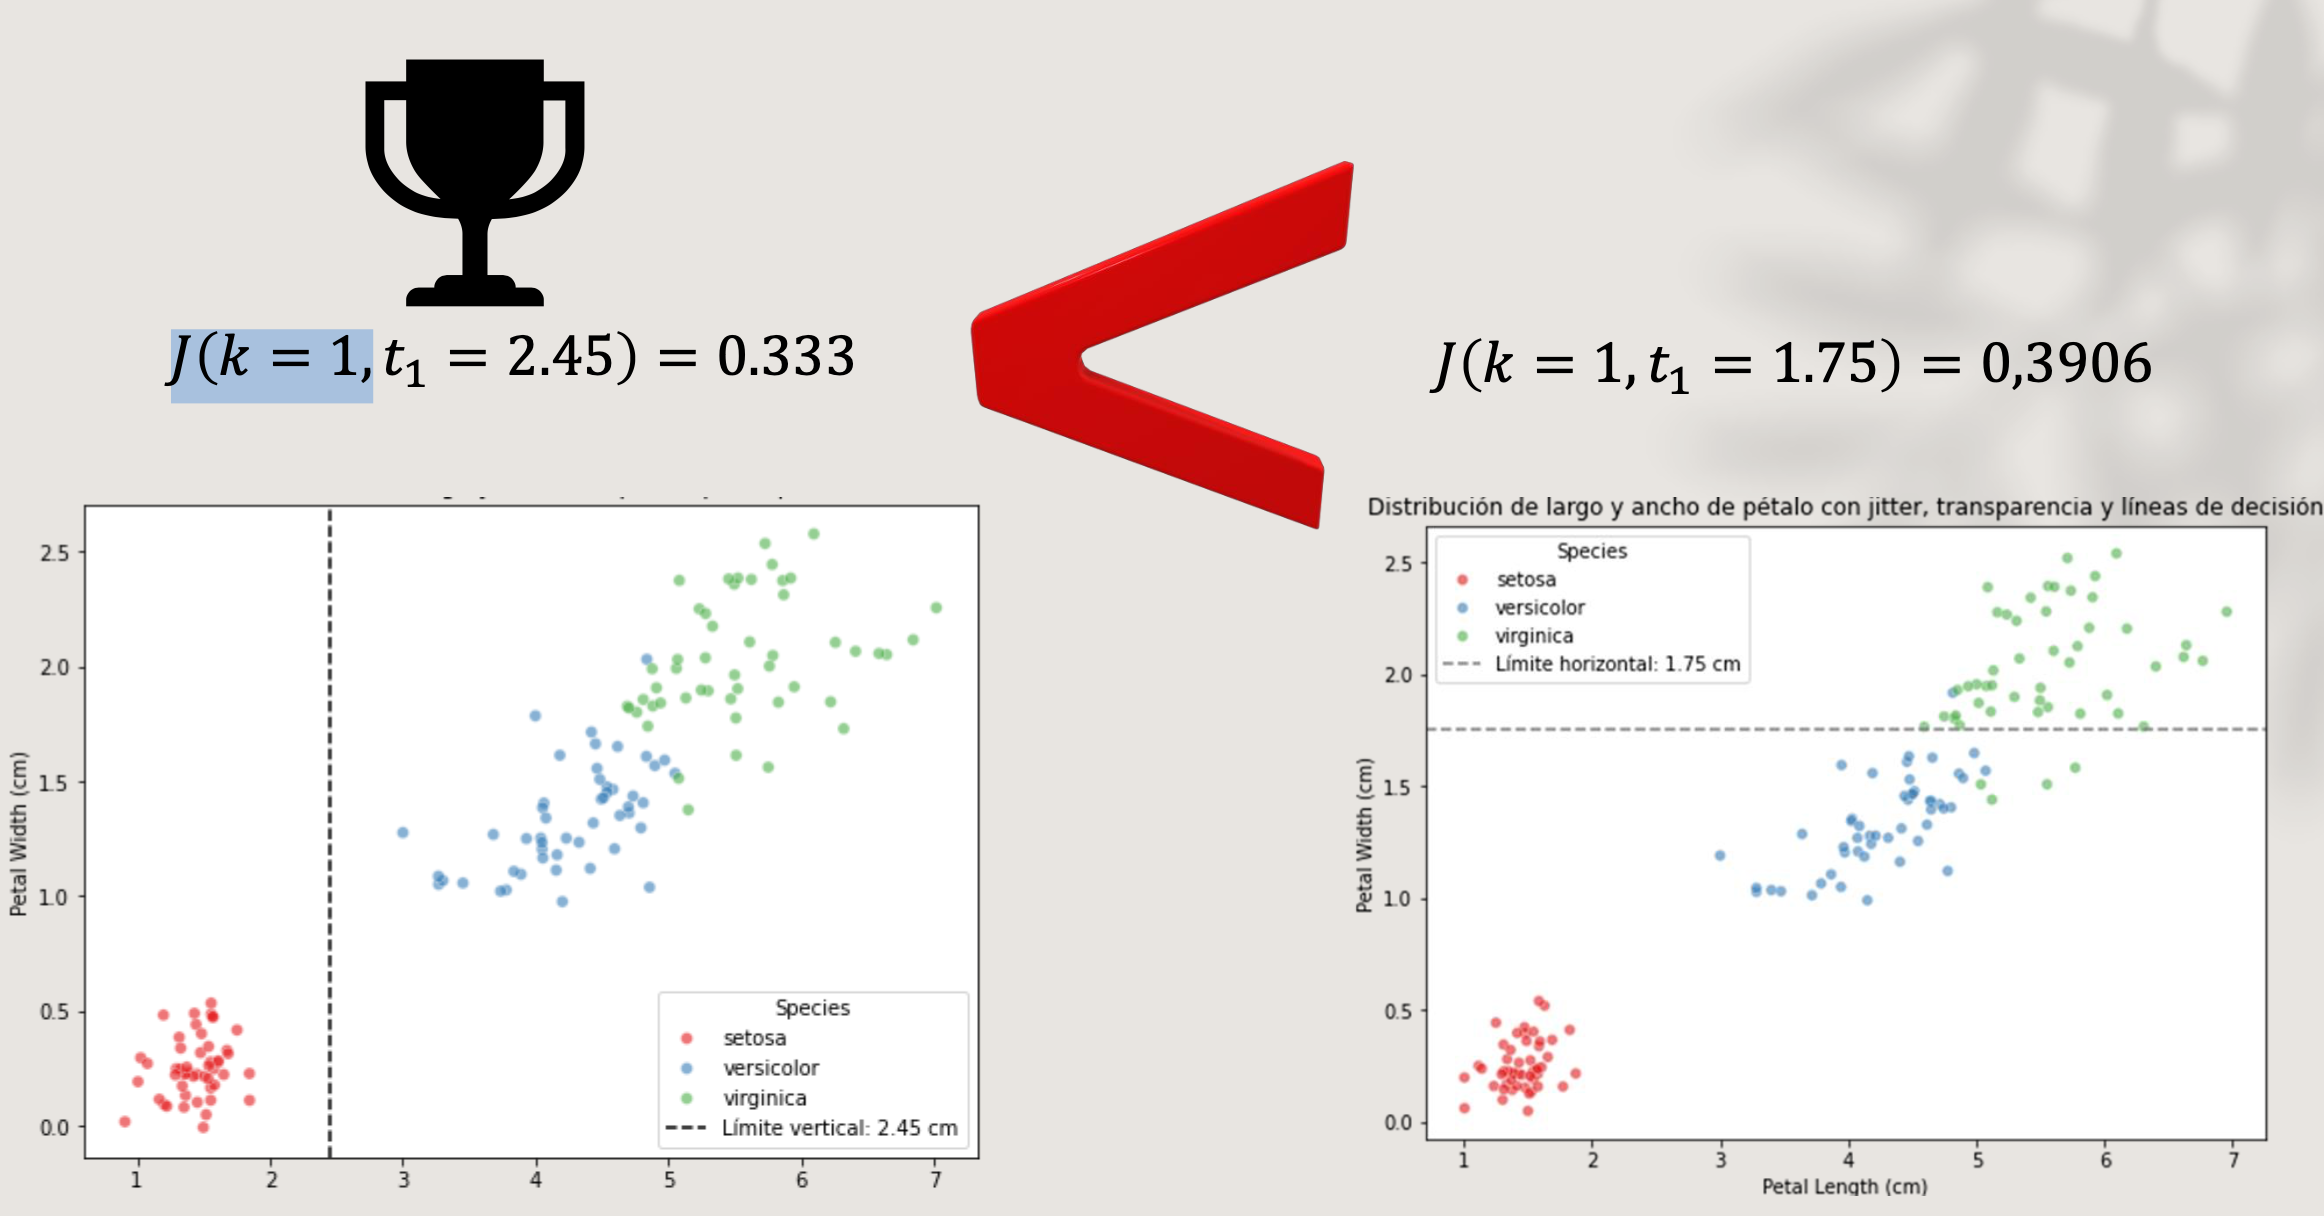

* **Pasos**
1. **Calcular todos los posibles umbrales**: son $n-1$ para cada variable. n son las observaciones. Cuando n aumenta, la cantidad de umbrales aumenta
    * Plantea todas las posibles combinaciones del par (variable, umbral t)
    * Si tengo 10 observaciones y 5 variables, hay 45 posibles combinaciones 
2. **Calcular índices Gini y función costo**
3. **Escoger el umbral con menor costo**: $mínimo J(k, t_k)$
    * Se queda con la combinación que tiene el mínimo costo
4. **Repetir**: que los nodos sean puros (**Gini = 0**). O se **alcance un criterio de parada** (profundidad máxima, mínimos de muestras, etc.)

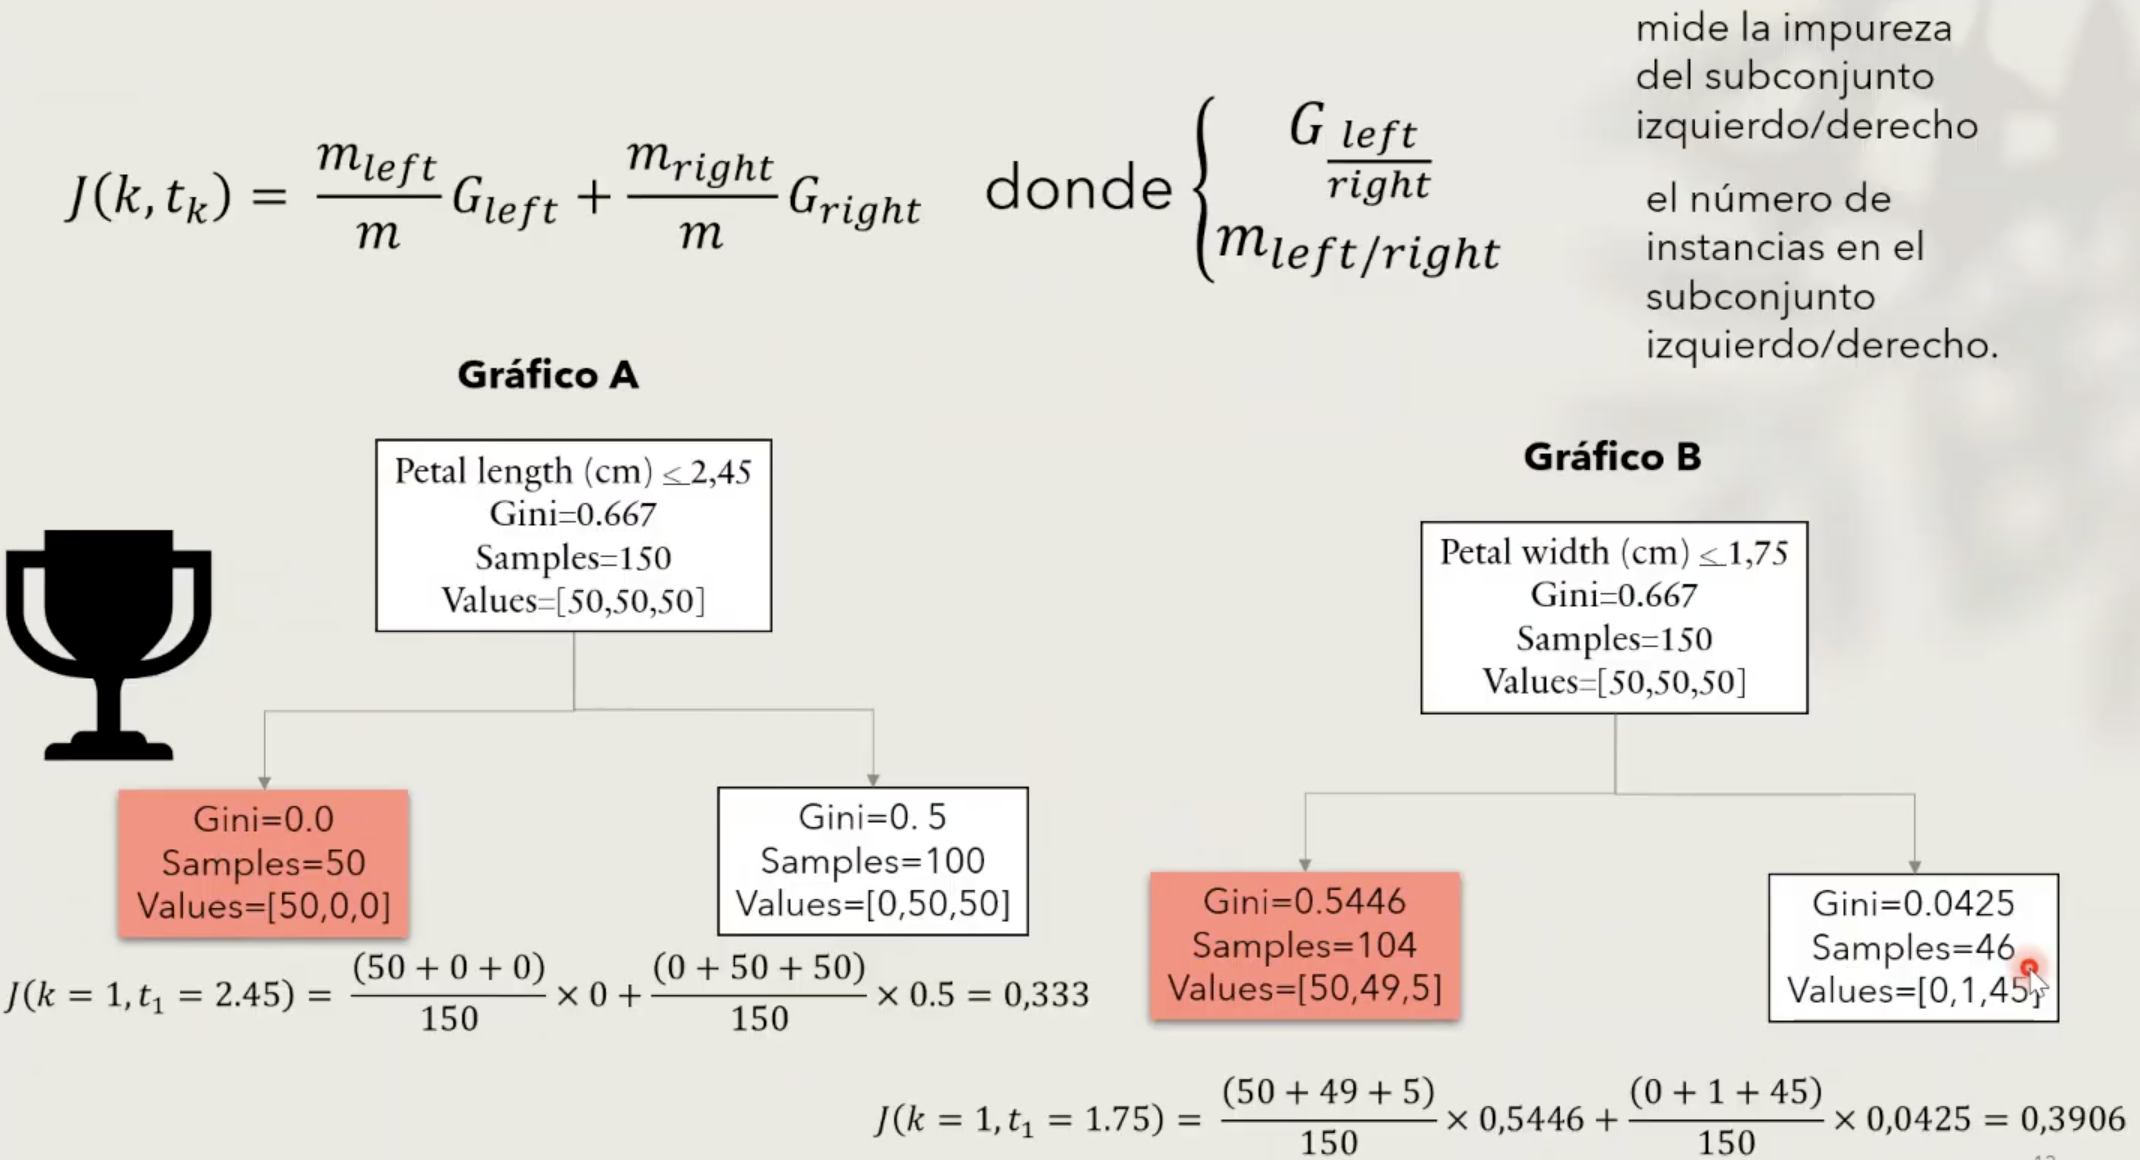

* ¿Que característica tomaria para designar un nodo raíz? y ¿por qué?
    * El árbol del **Gráfico A** porque tiene menor función de costo que el árbol del Gráfico B
* k: es la característica
* t: es el umbral

## Complejidad Computacional

* El algoritmo tiene en contra, que tiene una gran complejidad computacional
* Para hacer una predicción, el árbol se recorre desde la raíz hasta una hoja
* Como los árboles suelen estar balanceados, este recorrido implica pasar por aproximadamente **O(log(m))** nodos, siendo m el número de muestras
* En cada nodo solo se evalúa una característica, por lo que la predicción es rápida y no depende del número de características

* **¿Qué significa O(log(m))?**
    * **"O"** es la notación de "orden de magnitud" o "Big O", que indica el comportamiento del algoritmo en el peor caso
    * **"log(m)"** significa que el tiempo de ejecución crece de forma logarítmica con respecto al número de muestras m
    * Ejemplo intuitivo:
    * Si tenés: **1.000 muestras** => el algoritmo recorre aproximadamente log₂(1000) ≈ **10 nodos**
    * **1.000.000 muestras** => recorre log₂(1.000.000) ≈ **20 nodos**
    * Aunque el número de muestras crezca mucho, el número de pasos necesarios para hacer una predicción crece muy lentamente

## ¿Impureza de Gini o entropía?

* Por defecto, se usa **impureza de Gini** para dividir nodos
* Se puede usar **entropía** configurando el hiperparámetro criterion="entropy"
    * **Alta Entropía**: alto nivel de desorden (dispersión)
    * **Baja Entropía**: bajo nivel de desorden
* En aprendizaje automático, mide la impureza: entropía = 0 cuando todas las instancias son de una sola clase

$$H_i = - \Sigma_{h=1}^n p_{i,k} log_2(p_{i,k})$$

| Gini                                               | Entropía                                     |
| --                                                 | --                                           |
| se calcula más rápido => opción por defecto        | produce árboles ligeramente más equilibrados |
| tiende a aislar la clase más frecuente en una rama |                                              |

## Naturaleza del modelo

* En general, cuando se va a aplicar un modelo de machine learning, se divide la muestra en 2 subgrupos: entrenamiento y prueba. Con el de entrenamiento se encuentra el mejor modelo y después se contrasta con el de prueba
* En general, la mayoría de los modelos de ML, pide que se estandaricen las variables. En el caso de los árboles de decisión **no es necesario estandarizar las variables** 
* Los árboles de decisión son **modelos no paramétricos**: no tienen un número fijo de parámetros antes del entrenamiento, su estructura se adapta a los datos
* Esto les da mucha flexibilidad, pero también **alto riesgo de sobreajuste** si no se aplican restricciones
* Se definen zonas muy pequeñas, el set de datos se ajusta muy bien a los datos de entrenamiento pero no predice correctamente

## Prevenir el sobreajuste => restringir el número de nodos

* **Poda y ajuste**: ajuste de hiperparámetros para tener un modelo más simple y que sea fácilmente interpretable
* Un árbol con muchas hojas es mas propenso a un sobreajuste
* Un árbol sobreajustado funciona muy bien con los datos de entrenamiento, pero cuando se quiera predecir los datos prueba va a funcionar mal
* Lograr que el modelo funcione bien con los datos de entrenamiento y con los datos de prueba
* Se mira matriz de confusión de entrenamiento y de prueba. En la diagonal se tiene cuanto acerto y el resto lo mal clasificado. Si las proporciones son similares me quedo con el modelo.
* **Pre poda**: Definir el valor de los hiperparámetros:
    * Profundidad máxima
    * Número mínimo de datos en un nodo
    * Número mínimo de datos en una hoja
* **Post poda**: Poda de complejidad de costos, parámetro alfa. **¿Para qué sirve?**
    * **Si α = 0** => no se penaliza la complejidad => árbol muy grande (riesgo de sobreajuste)
    * **Si α aumenta** => se penaliza la complejidad => el árbol se poda más => modelo más simple (menos sobreajuste, pero puede
perder precisión)

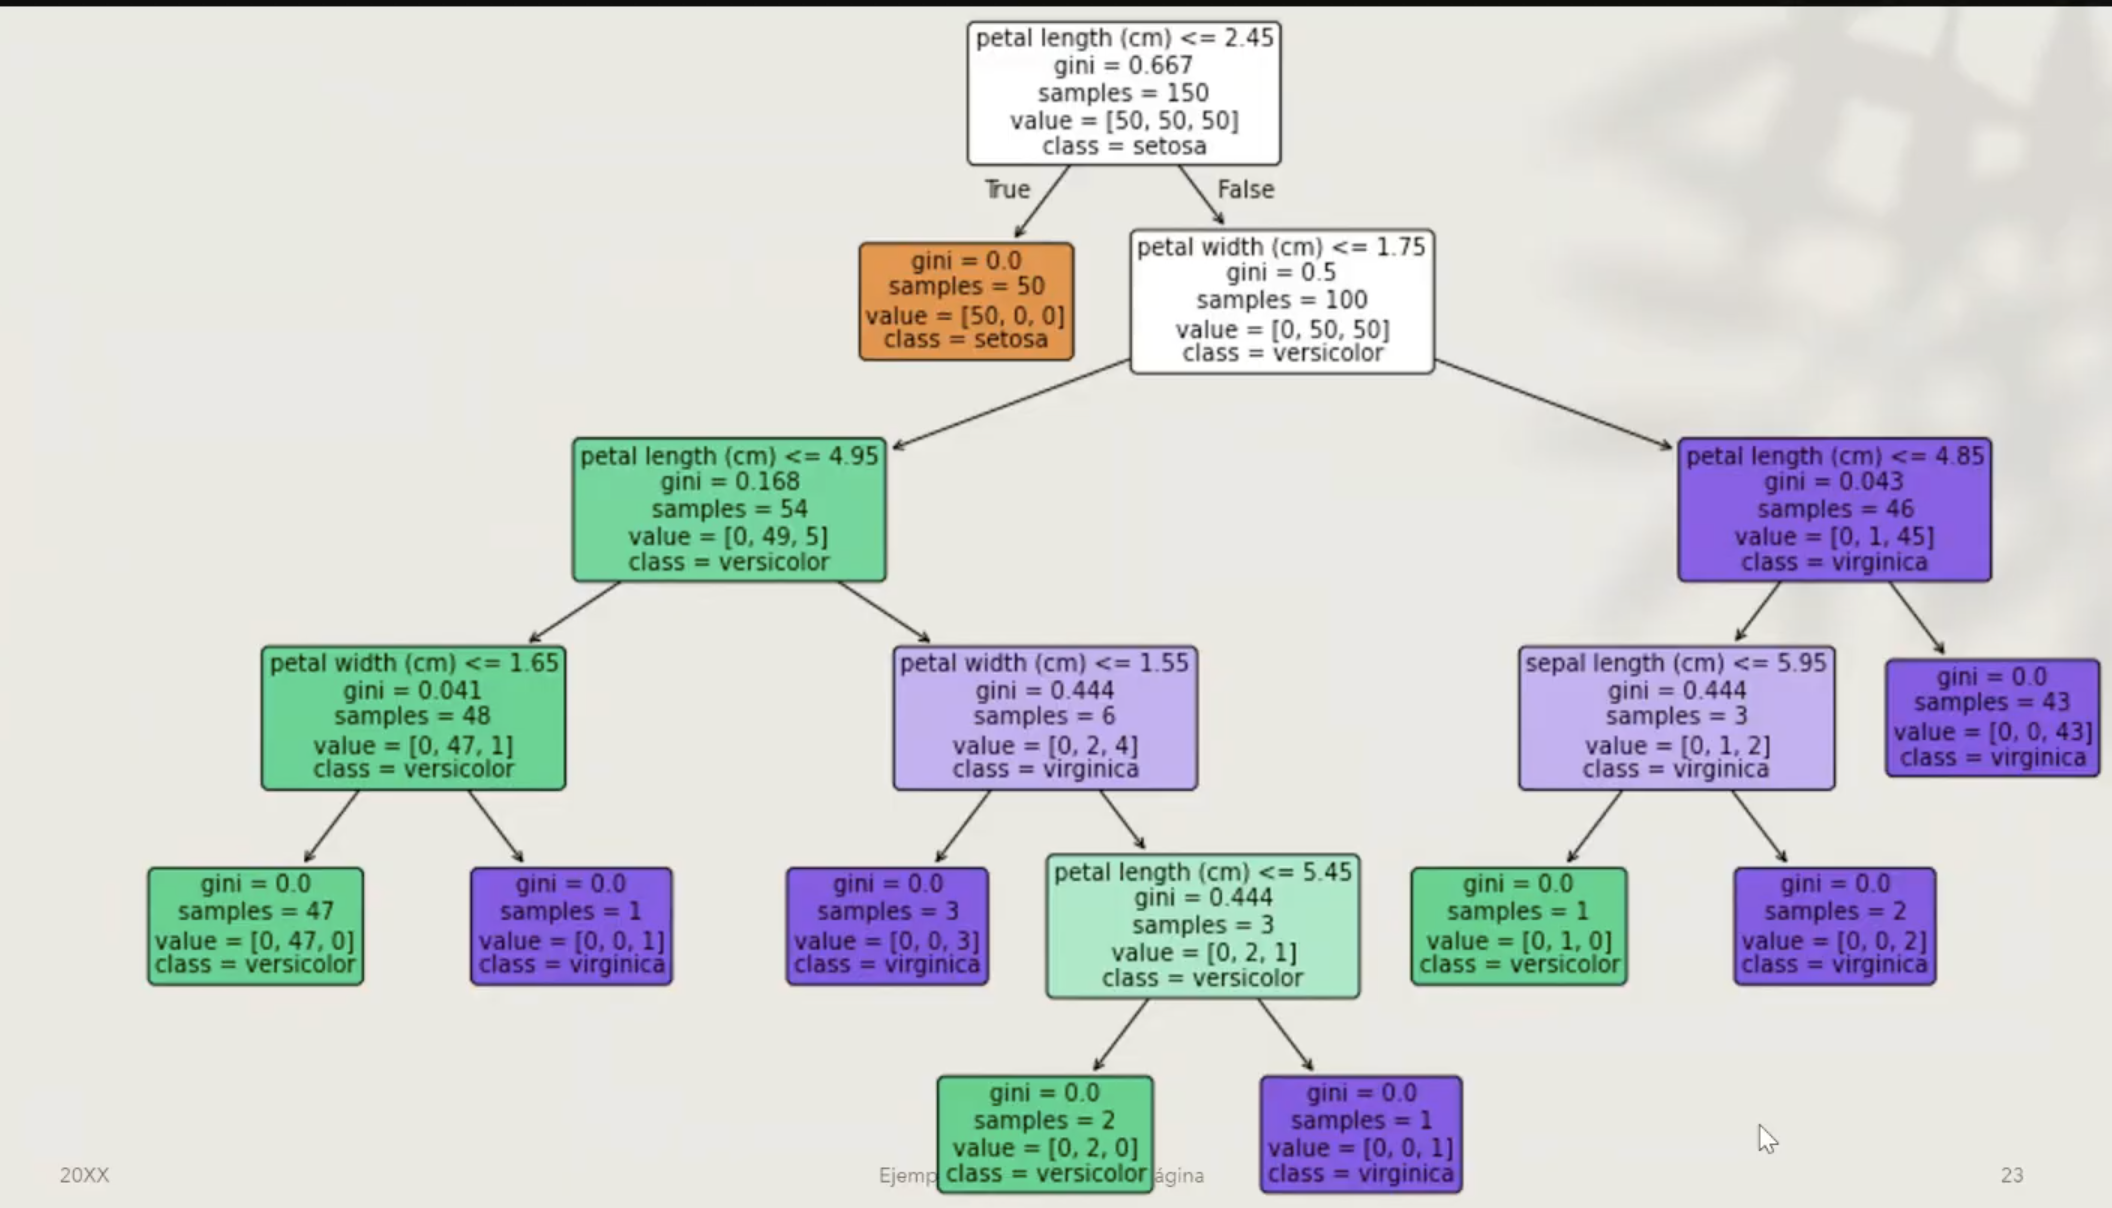

* ¿Por qué el árbol presenta sobreajuste?
    * Porque quedan pocos elementos en las hojas
    * Nodos con muchas muestras y una alta profundidad
* **Poda**: por ejemplo, que no genere hojas con menos de 5 observaciones
* ¿Cuál es la variable que tiene mayor relevancia y por que?
    * La que está en el nodo raíz
    * y luego las mas importantes son las más usada 
* ¿Se puede utilizar una misma variable mas de una vez en un árbol de decisión?
    * SI, mientras siga teniendo información

## Ventajas y Desventajas

* **Ventajas**:
    * Fácil de interpretar
    * Se puede ver cuáles son las características más relevantes (mas cerca de la raiz). La importancia de las variables va disminuyendo a medida que nos acercamos a las hojas
* **Desventajas**:
    * El tiempo de entrenamiento largos, ya que crece con el número de datos y características

## Observando el árbol, importancia de las variables

* Las variables que aparecen **más cerca de la raíz** (arriba) son las más importantes porque se usan primero para dividir los datos
* **petal length (cm)** aparece en la raíz => es la más importante. 
* **petal width (cm)** aparece varias veces => también muy relevante
* **sepal length (cm)** aparece 1 vez
* **sepal width (cm)** no aparece => casi irrelevante para este modelo

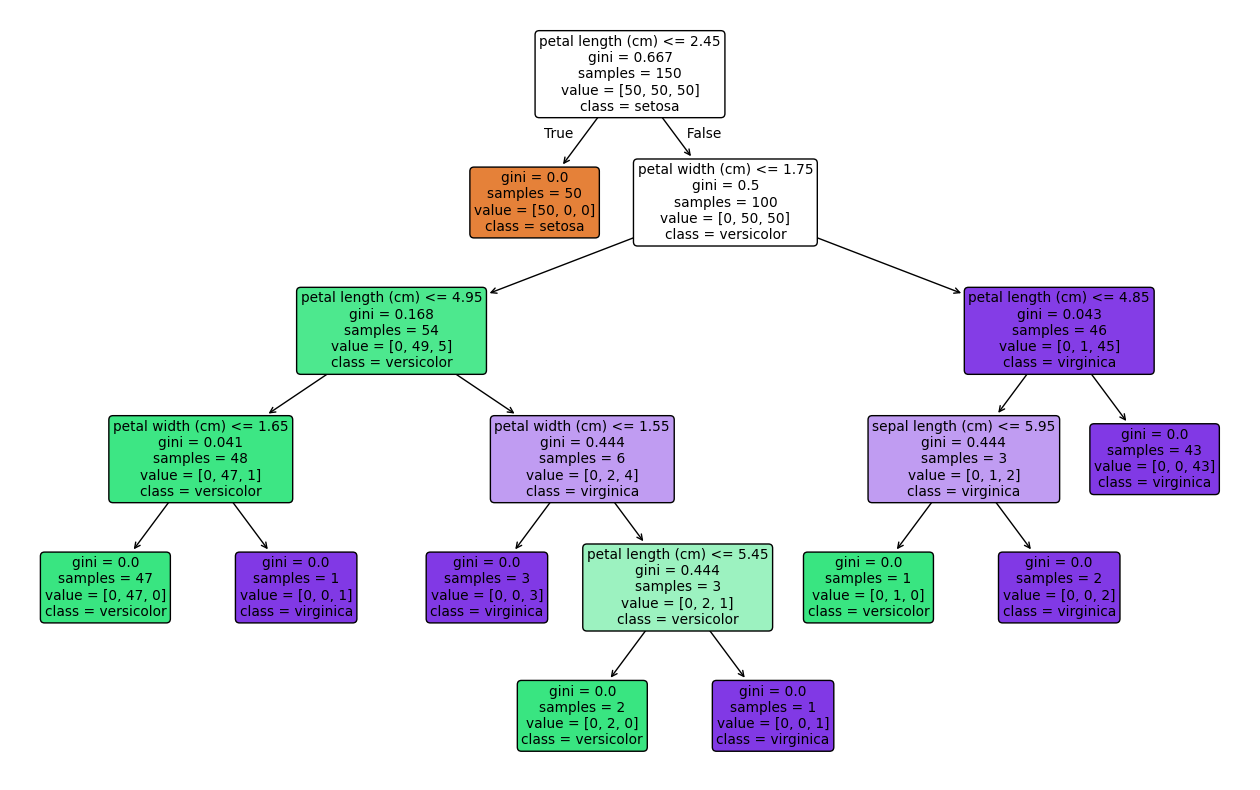

In [7]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

# Cargar el dataset Iris
iris = load_iris()

# Usar todas las características
X = iris.data
y = iris.target

# Crear y entrenar el árbol de clasificación (sin restricciones para ver el árbol completo)
tree_clf = DecisionTreeClassifier(random_state=42)
tree_clf.fit(X, y)

# Visualizar el árbol completo
plt.figure(figsize=(16, 10))  # aumentar tamaño para ver todo
plot_tree(tree_clf,
          feature_names=iris.feature_names,  # todas las variables
          class_names=iris.target_names,
          filled=True,
          rounded=True)
#plt.title("Árbol de clasificación completo (Iris)")
plt.show()

In [8]:
import pandas as pd

# Importancia de las variables
importances = tree_clf.feature_importances_
features = iris.feature_names

# Mostrar en tabla ordenada
pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

,Feature,Importance
2,petal length (cm),0.564056
3,petal width (cm),0.422611
0,sepal length (cm),0.013333
1,sepal width (cm),0.000000


# Árboles de regresión

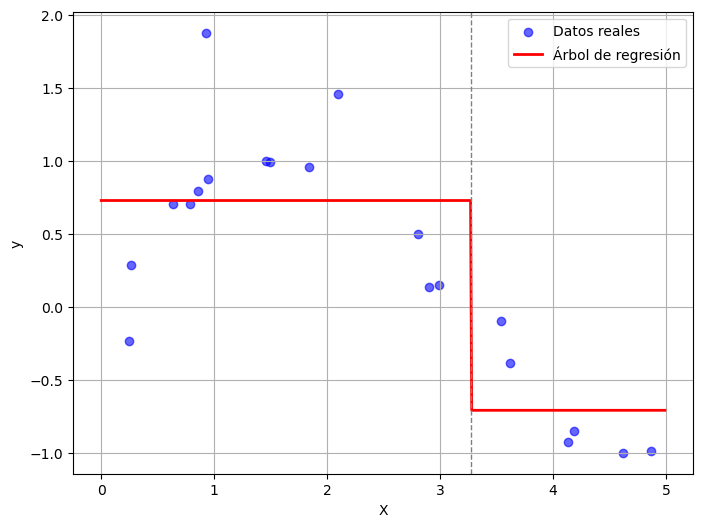

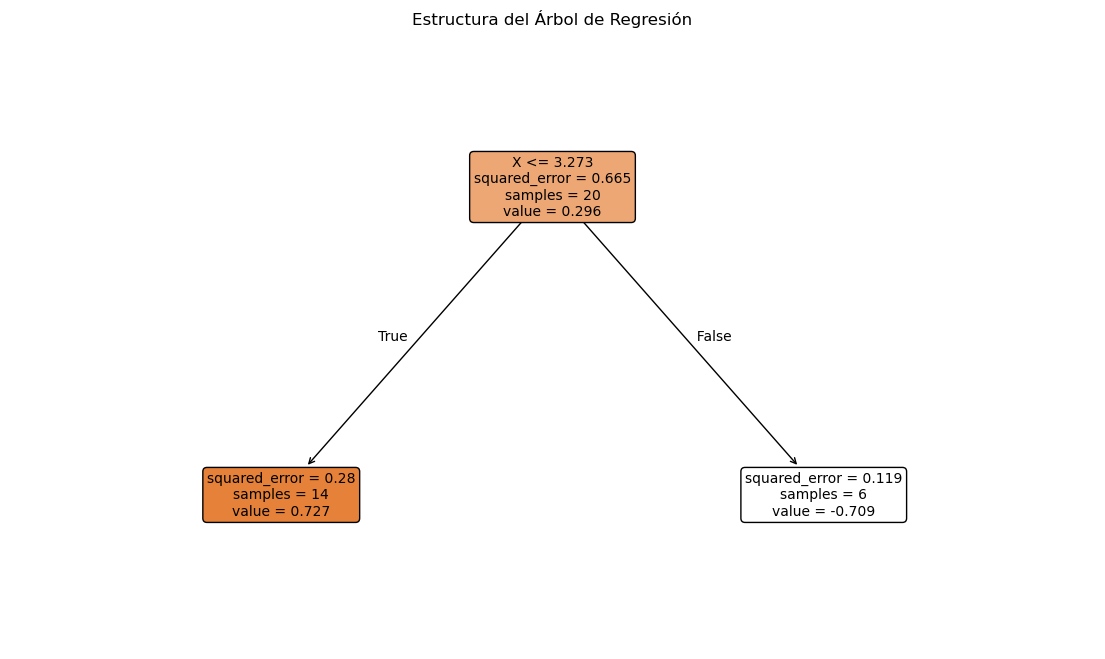

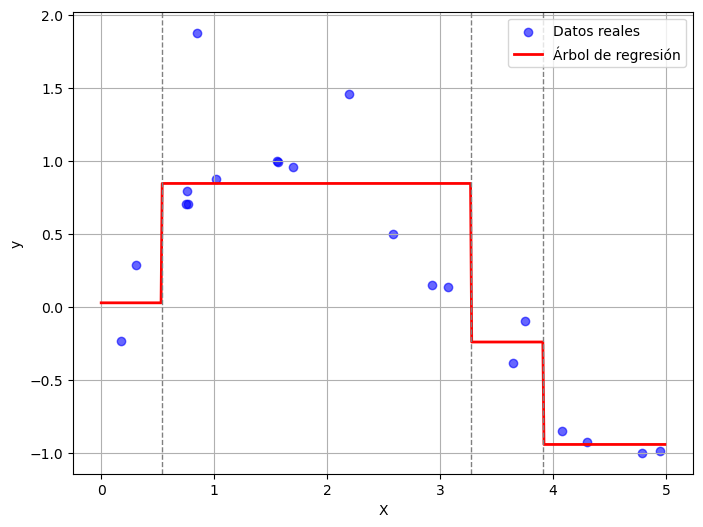

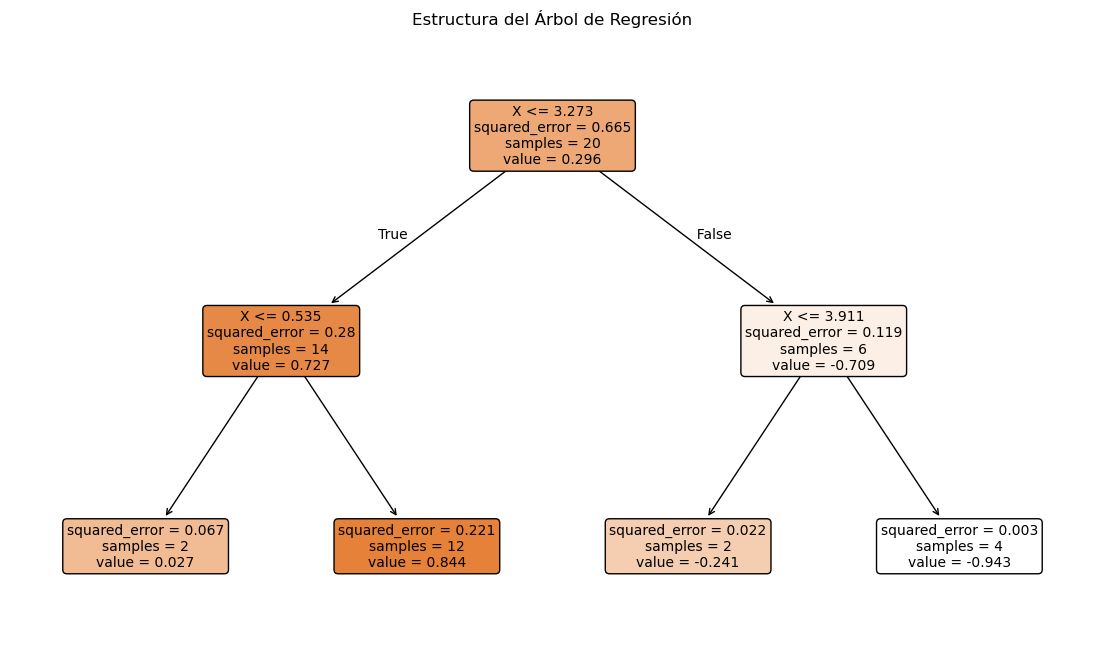

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree

# 1. Generar datos aleatorios (relación no lineal)
np.random.seed(42)
X = np.sort(5 * np.random.rand(20, 1), axis=0)  # valores entre 0 y 5
y = np.sin(X).ravel()                           # función seno
y[::5] += 3 * (0.5 - np.random.rand(len(y[::5])))  # añadir ruido

# 2. Entrenar árbol de regresión
tree_reg = DecisionTreeRegressor(max_depth=1, random_state=42)
tree_reg.fit(X, y)

# 3. Predicciones para graficar
X_test = np.arange(0.0, 5.0, 0.01).reshape(-1, 1)
y_pred = tree_reg.predict(X_test)

# 4. Graficar con jitter, transparencia y líneas de decisión
plt.figure(figsize=(8, 6))

# Agregar jitter a los puntos
jitter = 0.1 * np.random.randn(len(X))
plt.scatter(X + jitter.reshape(-1, 1), y, color="blue", alpha=0.6, label="Datos reales")

# Línea de regresión
plt.plot(X_test, y_pred, color="red", linewidth=2, label="Árbol de regresión")

# Líneas de decisión (límites de hojas)
thresholds = sorted(set(tree_reg.tree_.threshold[tree_reg.tree_.threshold != -2]))
for thresh in thresholds:
    plt.axvline(x=thresh, color='gray', linestyle='--', linewidth=1)

plt.xlabel("X")
plt.ylabel("y")
#plt.title("Árbol de Regresión con Jitter, Transparencia y Líneas de Decisión")
plt.legend()
plt.grid(True)
plt.show()

# 5. Visualizar estructura del árbol
plt.figure(figsize=(14, 8))
plot_tree(tree_reg, filled=True, rounded=True, feature_names=["X"], fontsize=10)
plt.title("Estructura del Árbol de Regresión")
plt.show()

# 2. Entrenar árbol de regresión
tree_reg = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg.fit(X, y)

# 3. Predicciones para graficar
X_test = np.arange(0.0, 5.0, 0.01).reshape(-1, 1)
y_pred = tree_reg.predict(X_test)

# 4. Graficar con jitter, transparencia y líneas de decisión
plt.figure(figsize=(8, 6))

# Agregar jitter a los puntos
jitter = 0.1 * np.random.randn(len(X))
plt.scatter(X + jitter.reshape(-1, 1), y, color="blue", alpha=0.6, label="Datos reales")

# Línea de regresión
plt.plot(X_test, y_pred, color="red", linewidth=2, label="Árbol de regresión")

# Líneas de decisión (límites de hojas)
thresholds = sorted(set(tree_reg.tree_.threshold[tree_reg.tree_.threshold != -2]))
for thresh in thresholds:
    plt.axvline(x=thresh, color='gray', linestyle='--', linewidth=1)

plt.xlabel("X")
plt.ylabel("y")
#plt.title("Árbol de Regresión con Jitter, Transparencia y Líneas de Decisión")
plt.legend()
plt.grid(True)
plt.show()

# 5. Visualizar estructura del árbol
plt.figure(figsize=(14, 8))
plot_tree(tree_reg, filled=True, rounded=True, feature_names=["X"], fontsize=10)
plt.title("Estructura del Árbol de Regresión")
plt.show()

## Información en un nodo

* **Condición de división (variable y umbral)**: Ejemplo: X ≤ 3.273 regla que separa los datos en ese nodo
* **Squared error**: error cuadrático medio (MSE) que se calcula con fórmula
* **Número de muestras (samples)**: Cantidad de observaciones que llegaron a ese nodo
* **Value**: es el promedio

A medida que se baja en el árbol (mayor profundidad), va disminuyendo el MSE porque cada vez se suma menos diferencias y cada vez se va a acercando mas al promedio

En raiz:
* samples = 20
* value = 0.296

$${squared \; error} = \Sigma_{i = 1}^{20} (y_i - 0.296)^2$$ 

* El **squared error** es la suma de los cuadrados de las diferencias entre cada valor real y el promedio del nodo
  1. promedia todas las observaciones (el value)
  2. a cada observacion le resta el promedio y lo eleva al cuadrado
  3. se suma y da el squared error

* En la gráfica se observan escalones, cuyo promedio se ven representados con las líneas rojas
* Se mide en vez de Gini, el error cuadrático medio
* En las hojas en vez de la clase, se observa el valor promedio con lo que va a predecir esa nueva observación

* Un árbol de regresión **divide el espacio en intervalos** (segmentos) según los umbrales que aprendió
* Dentro de cada intervalo, el árbol **predice el promedio** de los valores de y en ese segmento
* Por eso la línea roja no es suave como una regresión lineal, sino que tiene **tramos horizontales**:
    * Cada tramo corresponde a una **hoja del árbol**
    * Cuando el árbol cambia de hoja, la línea salta a otro nivel

* **Cómo interpretarlo**
* Las **líneas grises punteadas** son los **puntos de división** (thresholds) del árbol
* Entre dos líneas grises, la predicción es constante (el promedio de los datos en esa hoja)
* Si se aumentá max_depth, el árbol tendrá más divisiones => más tramos => se ajusta más a los datos (sobreajuste)
* Si se reduce max_depth, el árbol tendrá menos divisiones => menos tramos => modelo más simple (subajuste)

* **Función de coste**

$$J(k, t_k) = \dfrac{m_{left}}{m}MSE_{left} + \dfrac{m_{right}}{m}MSE_{right}$$

* IDEM que el árbol de clasificación pero con MSE (Error Cuadrático Medio)

## Ventajas y desventajas de árboles de decisión

* **Ventajas**:
    * Son sencillos de entender e interpretar
    * fáciles de usar
    * versátiles y potentes
* **Desventajas**:
    * los árboles de decisión funcionan mejor con límites de decisión ortogonales
    * **sensibilidad a pequeñas variaciones en los datos de entrenamiento**. Por ejemplo, se saca un dato (pétalo con 4.8 cm de largo y 1.8 cm de ancho) y ya no divide por la longitud del pétalo sino que divide por el ancho del pétalo

## Inestabilidad

* Pueden llegar a ser inestables
* Cuando no se pueda encontrar una función lineal (línea)

## Otros algoritmos: tabla comparativa de algoritmos de árboles de decisión

| Algoritmo | Criterio de división    | Tipo de variables input | Estrategia de poda                     |
| --        | --                      | --                      | --                                     |
| ID3       | Ganancia de información | solo categóricas        | no poda                                |
| CART      | Índice de Gini          | categóricas y numéricas | poda basada en el coste de complejidad |
| C4.5      | Ratio de ganancia       | categóricas y numéricas | poda basada en el error                |

* El algoritmo CART es el más utilizado de los 3

## Profundidad

* La profundidad aproximada de un árbol de decisión entrenado sin restricciones (es decir, sin límite en
max_depth, min_samples_split, etc.) depende de cuántas divisiones binarias se hacen antes de llegar a las hojas donde hay solo una observación

$$2^d \approx N$$
$$d = log_2 N$$

* La profundidad aproximada de un árbol de decisión entrenado sin restricciones en un conjunto de un millón de observaciones es de alrededor de 20 niveles

In [10]:
import math
math.log2(1000000)

19.931568569324174

In [11]:
math.log2(100)

6.643856189774724